# Classifiez automatiquement des informations - Modélisation

## 1. Import des modules et du dataset

In [62]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Validation croisé et finetunning
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
    cross_val_predict,
    StratifiedKFold
)
from sklearn.model_selection import train_test_split

# Import de modèles
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, precision_recall_curve, auc, precision_score, f1_score, classification_report, recall_score

# SMOTE
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline

#SHAP
import shap
from shap import TreeExplainer

In [63]:
df = pd.read_csv("../data/processed/dataset_clean.csv")

In [64]:
# On définit notre target
y = df["a_quitte_l_entreprise_Oui"]

# Création de notre df sans target
X = df.drop(columns=["a_quitte_l_entreprise_Oui"])

# Première séparation train test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.10, 
    random_state=42,
    stratify=y
)

df["a_quitte_l_entreprise_Oui"].value_counts()

a_quitte_l_entreprise_Oui
0.0    1233
1.0     237
Name: count, dtype: int64

## 2. Fonctions

### A. Validation de modèle

On définit nos métriques d'évaluation :
- **F1** : moyenne harmonique entre le rappel et la précision
- **Rappel** : proportion des vrais positifs
- **Precision** : proportion des prédictions positives qui sont effectivement correctes
- **PR AUC** : aire sous la courbe précision-rappel résumant le compromis entre précision et rappel à différents seuils
- **Time** : la durée d'entrainement de notre modèle

In [65]:
CV_DETAILS = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
def model_validation(model, X, y, use_smote=False):

    # Metriques chiffrées
    SCORING = ["f1", "precision", "recall", "average_precision"]

    steps = []
    if use_smote:
        steps.append(SMOTE(sampling_strategy=0.5, random_state=42))
    steps.append(model)

    pipeline = make_pipeline(*steps)

    cross_validation_result = cross_validate(
        pipeline,
        X, 
        y, 
        cv=CV_DETAILS, 
        scoring=SCORING, 
        return_train_score=True, 
        return_estimator=True
        )
    
    dict_resultats = {
        "F1": [np.mean(cross_validation_result["train_f1"]), np.mean(cross_validation_result["test_f1"])],
        "Precision": [np.mean(cross_validation_result["train_precision"]), 
                np.mean(cross_validation_result["test_precision"])],
        "Recall": [np.mean(cross_validation_result["train_recall"]), 
                 np.mean(cross_validation_result["test_recall"])],
        "PR AUC" : [np.mean(cross_validation_result["train_average_precision"]), 
                 np.mean(cross_validation_result["test_average_precision"])],
        "Time (sec)": [np.mean(cross_validation_result["fit_time"]), np.mean(cross_validation_result["score_time"])]
    }
    
    df_visuel = pd.DataFrame(dict_resultats, index=["Train (Fit)", "Test (Score)"])
    display(df_visuel)

### B. Matrice de confusion

In [66]:
# Matrice de confusion
def confusion_matrice(model, X, y):    
    y_pred = cross_val_predict(model, X, y, cv=CV_DETAILS)
    cm = confusion_matrix(y, y_pred)
    display("Matrice de confusion :", cm)

#### C. GridsearchCv / Optimisation de modèle

In [67]:
def optimisation_rfg(X_train, y_train):

    # parameters = {
    #     'n_estimators': [50, 100, 200],
    #     'max_depth': [5, 8, 10, 15, 20, 30],       
    #     'min_samples_split': [5, 10, 20, 30, 40],           
    #     'min_samples_leaf': [5, 10, 20, 30, 40, 50],            
    #     'max_features': ['sqrt', 'log2'],
    #     'class_weight': ['balanced'] 
    # }
    parameters = {
        'class_weight': ['balanced'],
        'max_depth': [5],
        'max_features': ['sqrt'],
        'min_samples_leaf': [50],
        'min_samples_split': [30],
        'n_estimators': [100]
        }
    clf = RandomForestClassifier()

    rfg = GridSearchCV(clf, parameters, cv=CV_DETAILS, scoring='recall', verbose=1)
    rfg.fit(X_train,y_train)
    return rfg

####  D.Graphique de feature Importance

In [68]:
# Prend en entrée un series construit à partir de best_model.feature_importances_
def graph_feature_imp(feature_imp):
    top_10 = feature_imp.head(10)

    plt.figure(figsize=(10, 6))

    top_10.sort_values(ascending=True).plot(
        kind='barh', 
        color='steelblue', 
        edgecolor='black', 
        linewidth=0.5
    )

    plt.title("Les 10 features les plus importantes", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Niveau d'importance", fontsize=12)
    plt.ylabel("Caractéristiques", fontsize=12)

    plt.grid(axis='x', linestyle='--', alpha=0.7)

    plt.tight_layout()

    plt.show()

## 3. Test de différents modèles

#### A. Modèle Etalon : Dummy Classifier

In [69]:
# Test du modele Dummy
clf = DummyClassifier()
display("Résultat Dummy Classifier")
model_validation(clf, X_train, y_train)
confusion_matrice(clf, X_train, y_train)

'Résultat Dummy Classifier'

,F1,Precision,Recall,PR AUC,Time (sec)
Train (Fit),0.0,0.0,0.0,0.160998,0.004869
Test (Score),0.0,0.0,0.0,0.160995,0.037202


'Matrice de confusion :'

array([[1110,    0],
       [ 213,    0]])

#### B. Modèle Linéaire : Regression logistique

In [70]:
# Test du modele Regression logistique
clf = LogisticRegression()
display("Résultat Regression logistique")
model_validation(clf, X_train, y_train)
confusion_matrice(clf, X_train, y_train)


# Test du modele de regression logistique avec normalisation
pipeline_logistic_regression = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic_regression', LogisticRegression(class_weight='balanced'))
])
display("Résultat Regression logistique avec normalisation")
model_validation(pipeline_logistic_regression, X_train, y_train)
confusion_matrice(pipeline_logistic_regression, X_train, y_train)

'Résultat Regression logistique'

,F1,Precision,Recall,PR AUC,Time (sec)
Train (Fit),0.228625,0.762485,0.143055,0.497909,0.061759
Test (Score),0.198207,0.575000,0.122702,0.449355,0.022911


'Matrice de confusion :'

array([[1099,   11],
       [ 187,   26]])

'Résultat Regression logistique avec normalisation'

,F1,Precision,Recall,PR AUC,Time (sec)
Train (Fit),0.531528,0.402375,0.782862,0.625593,0.018506
Test (Score),0.475017,0.356254,0.718162,0.555241,0.021859


'Matrice de confusion :'

array([[831, 279],
       [ 60, 153]])

#### C. Modèle non linéaire : Random Forest Classifier

In [71]:
# Test du modele Random Forest Classifier
clf = RandomForestClassifier()
display("Résultat Random Forest Classifier")
model_validation(clf, X_train, y_train)
confusion_matrice(clf, X_train, y_train)

'Résultat Random Forest Classifier'

,F1,Precision,Recall,PR AUC,Time (sec)
Train (Fit),1.000000,1.000000,1.000000,1.0000,0.286227
Test (Score),0.250733,0.782857,0.150388,0.5408,0.050916


'Matrice de confusion :'

array([[1099,   11],
       [ 178,   35]])

## 4. Optimisation d'un modèle

### A. Tests Hyperparamètres

In [72]:
rfg = optimisation_rfg(X_train, y_train)
display(rfg.best_params_)
display(rfg.best_score_)

Fitting 5 folds for each of 1 candidates, totalling 5 fits


{'class_weight': 'balanced',
 'max_depth': 5,
 'max_features': 'sqrt',
 'min_samples_leaf': 50,
 'min_samples_split': 30,
 'n_estimators': 100}

np.float64(0.7145071982281286)

In [73]:
display("Résultat Random Forest Classifier")
model_validation(rfg, X_train, y_train)
confusion_matrice(rfg, X_train, y_train)

'Résultat Random Forest Classifier'

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits


,F1,Precision,Recall,PR AUC,Time (sec)
Train (Fit),0.539145,0.411332,0.782896,0.624421,1.298940
Test (Score),0.486268,0.375227,0.695460,0.552433,0.051773


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits


'Matrice de confusion :'

array([[849, 261],
       [ 64, 149]])

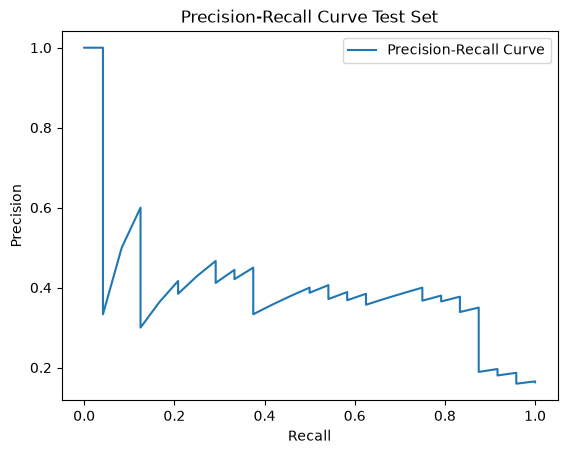

In [74]:
y_proba_test = rfg.predict_proba(X_test)[:,1]

precision_test, recall_test, thresholds_test = precision_recall_curve(
    y_test, 
    y_proba_test
)

plt.plot(recall_test, precision_test, label="Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Test Set")
plt.legend()
plt.show()


### B.Feature engineering

In [75]:
X["ratio_salaire_anciennete"] = X["revenu_mensuel"] / (X["annees_dans_l_entreprise"] + 1)


X["score_satisfaction_moyen"] = ((X["satisfaction_employee_environnement"] 
                                  + X["satisfaction_employee_nature_travail"] 
                                      + X["satisfaction_employee_equipe"] + X["satisfaction_employee_equilibre_pro_perso"]) / 4)


X["evolution_carriere"] = X["annees_depuis_la_derniere_promotion"] / (X["annees_dans_l_entreprise"] + 1)

X["formation_par_an"] = X["nb_formations_suivies"] / (X["annees_dans_l_entreprise"] +1)

X_trainV2, X_testV2, y_trainV2, y_testV2 = train_test_split(
    X,
    y,
    test_size=0.10,
    random_state=42,
    stratify=y
)

In [76]:
rfg = optimisation_rfg(X_trainV2, y_trainV2)
display(rfg.best_params_)
display(rfg.best_score_)

Fitting 5 folds for each of 1 candidates, totalling 5 fits


{'class_weight': 'balanced',
 'max_depth': 5,
 'max_features': 'sqrt',
 'min_samples_leaf': 50,
 'min_samples_split': 30,
 'n_estimators': 100}

np.float64(0.6953488372093023)

heure_supplementaires_Oui                    0.175940
revenu_mensuel                               0.157566
annees_dans_l_entreprise                     0.107080
nombre_participation_pee                     0.104743
formation_par_an                             0.079819
tranche_age                                  0.076606
score_satisfaction_moyen                     0.075399
distance_domicile_travail                    0.032235
ratio_salaire_anciennete                     0.027275
satisfaction_employee_environnement          0.025968
evolution_carriere                           0.022318
satisfaction_employee_nature_travail         0.016482
poste_Cadre Commercial                       0.012063
poste_Consultant                             0.011034
augmentation_salaire_precedente              0.010723
statut_marital_Marié(e)                      0.008733
Diff_evaluation                              0.007954
nombre_experiences_precedentes_4+            0.007017
annees_depuis_la_derniere_pr

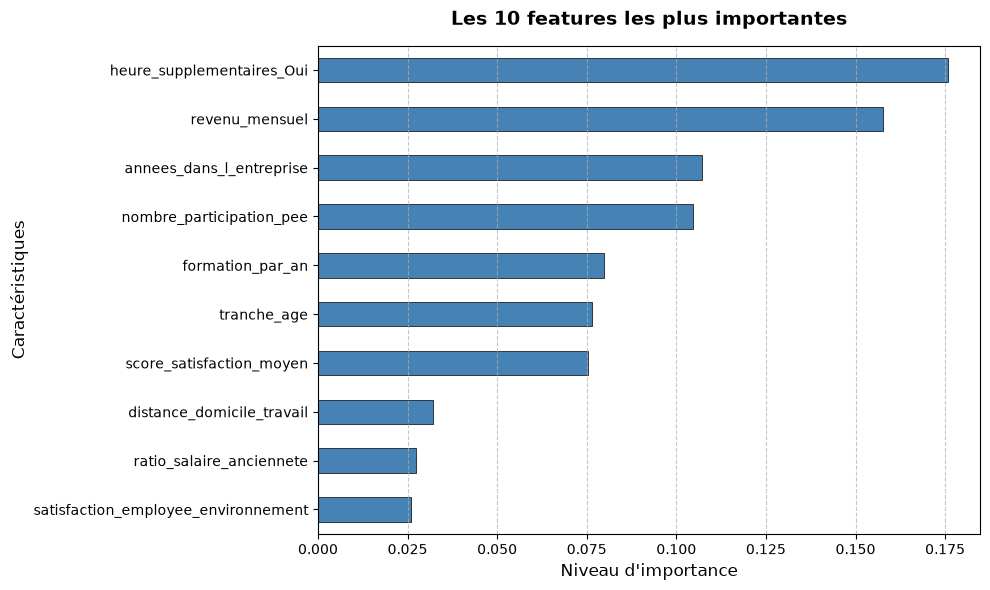

In [77]:
best_model = rfg.best_estimator_
importances = best_model.feature_importances_
feature_imp = pd.Series(
    importances, index=X_trainV2.columns
).sort_values(ascending=False)
display(feature_imp)

graph_feature_imp(feature_imp)

### C. Utilisation de Smote

In [78]:
display("Résultat Random Forest Classifier")
model_validation(rfg, X_trainV2, y_trainV2, use_smote=True)
confusion_matrice(rfg, X_trainV2, y_trainV2)

'Résultat Random Forest Classifier'

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits


,F1,Precision,Recall,PR AUC,Time (sec)
Train (Fit),0.611763,0.579057,0.649006,0.665822,1.694162
Test (Score),0.534525,0.533834,0.545183,0.557868,0.046445


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits


'Matrice de confusion :'

array([[861, 249],
       [ 69, 144]])

In [79]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_trainV2, y_trainV2)
display(X_trainV2)
display(X_train_smote)

,revenu_mensuel,annees_dans_l_entreprise,nombre_participation_pee,nb_formations_suivies,distance_domicile_travail,niveau_education,annees_depuis_la_derniere_promotion,satisfaction_employee_environnement,satisfaction_employee_nature_travail,satisfaction_employee_equipe,...,domaine_etude_Infra & Cloud,domaine_etude_Marketing,domaine_etude_Transformation Digitale,heure_supplementaires_Oui,nombre_experiences_precedentes_2-3,nombre_experiences_precedentes_4+,ratio_salaire_anciennete,score_satisfaction_moyen,evolution_carriere,formation_par_an
982,2610,4,3,2,7,3,0,4,3,4,...,1.0,0.0,0.0,0.0,0.0,0.0,522.000000,3.50,0.000000,0.400000
621,6201,18,1,1,1,2,4,2,4,4,...,1.0,0.0,0.0,1.0,0.0,0.0,326.368421,3.00,0.210526,0.052632
1263,2766,5,3,6,12,3,0,2,2,2,...,0.0,0.0,1.0,0.0,0.0,1.0,461.000000,2.00,0.000000,1.000000
1094,5473,8,0,5,9,2,7,1,1,4,...,0.0,0.0,1.0,0.0,0.0,0.0,608.111111,2.50,0.777778,0.555556
578,5980,15,0,2,2,4,4,1,1,4,...,1.0,0.0,0.0,1.0,0.0,1.0,373.750000,2.25,0.250000,0.125000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107,5744,6,0,1,5,3,0,3,3,4,...,0.0,1.0,0.0,1.0,0.0,0.0,820.571429,3.25,0.000000,0.142857
963,6893,7,1,3,2,2,1,2,1,4,...,1.0,0.0,0.0,0.0,1.0,0.0,861.625000,2.50,0.125000,0.375000
734,2451,4,1,3,8,1,1,2,1,1,...,1.0,0.0,0.0,0.0,0.0,0.0,490.200000,1.50,0.200000,0.600000
1315,6962,1,1,2,2,4,0,4,2,4,...,0.0,0.0,0.0,1.0,0.0,1.0,3481.000000,3.25,0.000000,1.000000


,revenu_mensuel,annees_dans_l_entreprise,nombre_participation_pee,nb_formations_suivies,distance_domicile_travail,niveau_education,annees_depuis_la_derniere_promotion,satisfaction_employee_environnement,satisfaction_employee_nature_travail,satisfaction_employee_equipe,...,domaine_etude_Infra & Cloud,domaine_etude_Marketing,domaine_etude_Transformation Digitale,heure_supplementaires_Oui,nombre_experiences_precedentes_2-3,nombre_experiences_precedentes_4+,ratio_salaire_anciennete,score_satisfaction_moyen,evolution_carriere,formation_par_an
0,2610,4,3,2,7,3,0,4,3,4,...,1.000000,0.0,0.000000,0.000000,0.000000,0.000000,522.000000,3.500000,0.000000,0.400000
1,6201,18,1,1,1,2,4,2,4,4,...,1.000000,0.0,0.000000,1.000000,0.000000,0.000000,326.368421,3.000000,0.210526,0.052632
2,2766,5,3,6,12,3,0,2,2,2,...,0.000000,0.0,1.000000,0.000000,0.000000,1.000000,461.000000,2.000000,0.000000,1.000000
3,5473,8,0,5,9,2,7,1,1,4,...,0.000000,0.0,1.000000,0.000000,0.000000,0.000000,608.111111,2.500000,0.777778,0.555556
4,5980,15,0,2,2,4,4,1,1,4,...,1.000000,0.0,0.000000,1.000000,0.000000,1.000000,373.750000,2.250000,0.250000,0.125000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2215,3848,2,0,2,3,1,1,2,3,3,...,0.265851,0.0,0.000000,0.265851,0.000000,1.000000,1282.757868,2.867074,0.421950,0.911383
2216,10413,13,0,2,6,3,7,2,1,3,...,0.353910,0.0,0.646090,0.000000,0.000000,1.000000,725.923288,2.484568,0.536430,0.185636
2217,9032,1,1,2,9,4,0,1,2,1,...,0.000000,1.0,0.000000,0.499334,0.500666,0.499334,3691.935054,2.249667,0.332889,1.000000
2218,6639,5,1,2,7,3,0,2,3,4,...,1.000000,0.0,0.000000,0.266019,0.000000,1.000000,989.081215,3.000000,0.044337,0.403236


In [80]:
rfg_smote = optimisation_rfg(X_train_smote, y_train_smote)
model_validation(rfg_smote, X_train_smote, y_train_smote)
confusion_matrice(rfg_smote, X_train_smote, y_train_smote)

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits


,F1,Precision,Recall,PR AUC,Time (sec)
Train (Fit),0.894338,0.934115,0.857883,0.966895,1.924306
Test (Score),0.877607,0.917427,0.842342,0.957311,0.061608


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits


'Matrice de confusion :'

array([[1024,   86],
       [ 179,  931]])

heure_supplementaires_Oui                    0.263253
nombre_participation_pee                     0.114227
statut_marital_Marié(e)                      0.080605
tranche_age                                  0.048089
satisfaction_employee_nature_travail         0.045809
score_satisfaction_moyen                     0.043419
statut_marital_Divorcé(e)                    0.040572
annees_dans_l_entreprise                     0.040246
satisfaction_employee_environnement          0.031058
poste_Consultant                             0.029674
poste_Représentant Commercial                0.027878
revenu_mensuel                               0.026270
nombre_experiences_precedentes_4+            0.023726
domaine_etude_Infra & Cloud                  0.023154
poste_Cadre Commercial                       0.022155
satisfaction_employee_equilibre_pro_perso    0.022007
formation_par_an                             0.021604
genre_M                                      0.019527
satisfaction_employee_equipe

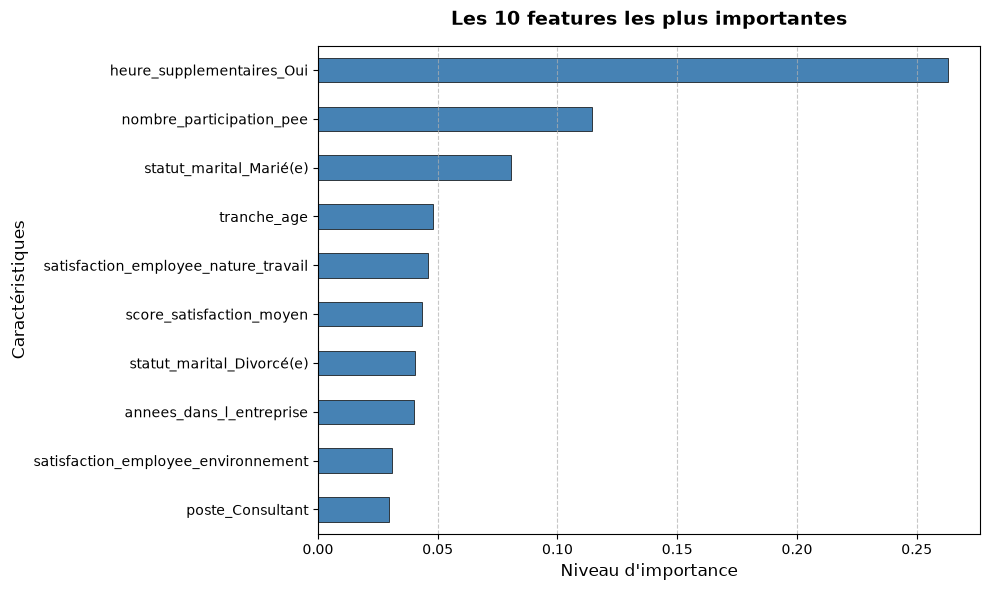

In [85]:
best_model = rfg_smote.best_estimator_
importances = best_model.feature_importances_
feature_imp = pd.Series(
    importances, index=X_trainV2.columns
).sort_values(ascending=False)
display(feature_imp)

graph_feature_imp(feature_imp)

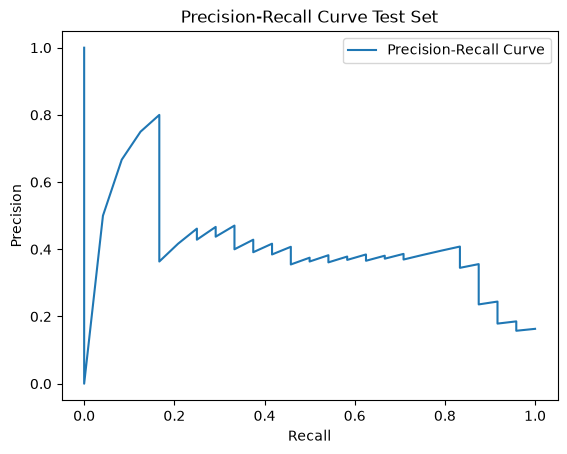

In [86]:
y_proba_test = rfg_smote.predict_proba(X_testV2)[:, 1]

precision_test, recall_test, thresholds_test = precision_recall_curve(
    y_testV2, y_proba_test
)

plt.plot(recall_test, precision_test, label="Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Test Set")
plt.legend()
plt.show()

On modifie le seuil pour obtenir un recall de 80%.

In [90]:
idx = np.argmin(np.abs(recall_test - 0.80))
print(f"Recall : {recall_test[idx]:.4f}")
print(f"Precision : {precision_test[idx]:.4f}")
if idx < len(thresholds_test):
  print(f"Seuil (Threshold) : {thresholds_test[idx]:.4f}")

Recall : 0.7917
Precision : 0.3958
Seuil (Threshold) : 0.3675


### Interprétation

In [ ]:
#
# Recréer un bon modèle random forest regressor avec les bons hyperparamètres pour l'entrer dedans ici
#
explainer = TreeExplainer(rfg_smote, approximate=True)
shap_values_train = explainer(X_testV2)
shap.plots.beeswarm(shap_values_train[:,:,1])

InvalidModelError: Model type not yet supported by TreeExplainer: <class 'sklearn.model_selection._search.GridSearchCV'>

Ce beeswarm nous permet de déduire les choses suivantes :
- La non-participation au PEE et la réalisation d'heure supps sont les 2 indices les plus fiables pour anticiper un départ
- Les célibataires (3ème statut_marital) ont plus de chances de quitter l'entreprise
- Les faibles tranches d'age ainsi que les faibles revenus augmentent les chances de départ